# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown
from google.colab import files

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.unicode_minus"] = False

## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [2]:
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)
df.columns = df.columns.str.strip()
print(f"Завантажено: {filename}")
display(df.head())

Saving house_price_regression_dataset.csv to house_price_regression_dataset.csv
Завантажено: house_price_regression_dataset.csv


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [3]:
if "df" not in globals():
    import kagglehub
    folder = Path(kagglehub.dataset_download("prokshitha/home-value-insights"))
    csv_files = sorted(folder.rglob("*.csv"))
    if not csv_files:
        raise FileNotFoundError("CSV-файл у датасеті Kaggle не знайдено")
    preferred = [p for p in csv_files if "house" in p.name.lower()]
    csv_path = (preferred or csv_files)[0]
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    print(f"Завантажено з Kaggle: {csv_path.name}")
else:
    print("Дані вже завантажено з локального CSV-файлу")
display(df.head())

Дані вже завантажено з локального CSV-файлу


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [4]:
display(df.head(10))
print("Розмір таблиці:", df.shape)
print("Типи даних та інформація:")
df.info()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06
5,3944,5,3,1990,2.475930,2,8,8.797970e+05
6,3671,1,2,2012,4.911960,0,1,8.144279e+05
7,3419,1,1,1972,2.805281,1,1,7.034131e+05
8,630,3,3,1997,1.014286,1,8,1.738750e+05
9,2185,4,2,1981,3.941604,2,5,5.041765e+05


Розмір таблиці: (1000, 8)
Типи даних та інформація:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [5]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [6]:
display(df.isna().sum().rename("Пропущені значення").to_frame())

,Пропущені значення
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [7]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Square_Footage,1000.0,2815.422000,1255.514921,503.000000,1749.500000,2862.500000,3849.500000,4.999000e+03
Num_Bedrooms,1000.0,2.990000,1.427564,1.000000,2.000000,3.000000,4.000000,5.000000e+00
Num_Bathrooms,1000.0,1.973000,0.820332,1.000000,1.000000,2.000000,3.000000,3.000000e+00
Year_Built,1000.0,1986.550000,20.632916,1950.000000,1969.000000,1986.000000,2004.250000,2.022000e+03
Lot_Size,1000.0,2.778087,1.297903,0.506058,1.665946,2.809740,3.923317,4.989303e+00
Garage_Size,1000.0,1.022000,0.814973,0.000000,0.000000,1.000000,2.000000,2.000000e+00
Neighborhood_Quality,1000.0,5.615000,2.887059,1.000000,3.000000,6.000000,8.000000,1.000000e+01
House_Price,1000.0,618861.018647,253568.058375,111626.853424,401648.228909,628267.291129,827141.277637,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [8]:
display(df["Neighborhood_Quality"].value_counts(dropna=False).sort_index())

,count
Neighborhood_Quality,
1,91
2,105
3,85
4,99
5,109
6,101
7,102
8,97
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

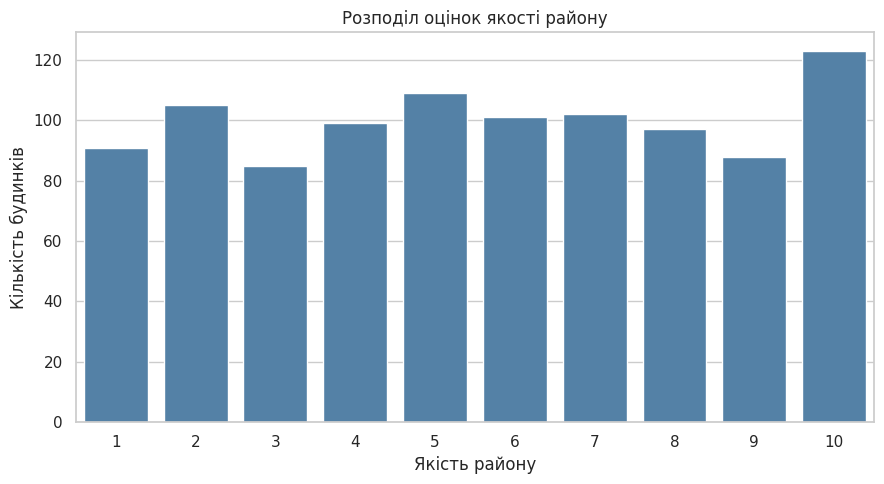

In [9]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Neighborhood_Quality", order=sorted(df["Neighborhood_Quality"].dropna().unique()), color="steelblue")
plt.title("Розподіл оцінок якості району")
plt.xlabel("Якість району")
plt.ylabel("Кількість будинків")
plt.tight_layout()
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [10]:
display(df["Num_Bathrooms"].value_counts(dropna=False).sort_index())

,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

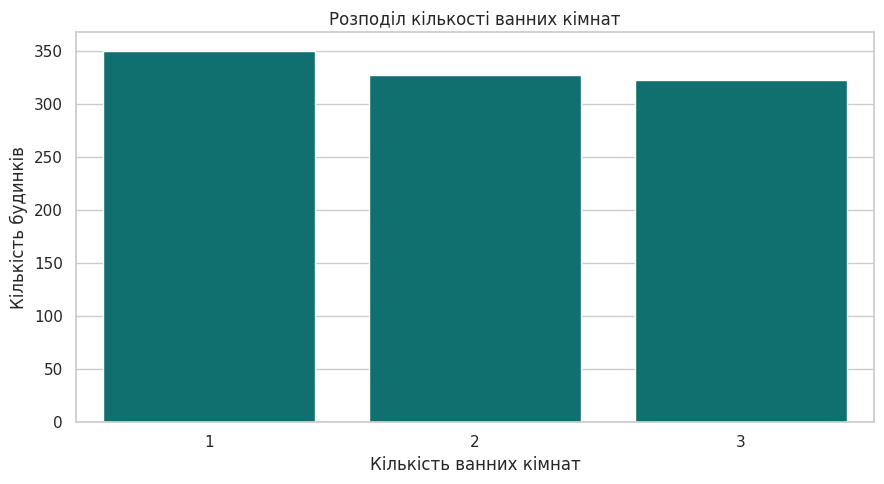

In [11]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Num_Bathrooms", order=sorted(df["Num_Bathrooms"].dropna().unique()), color="teal")
plt.title("Розподіл кількості ванних кімнат")
plt.xlabel("Кількість ванних кімнат")
plt.ylabel("Кількість будинків")
plt.tight_layout()
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

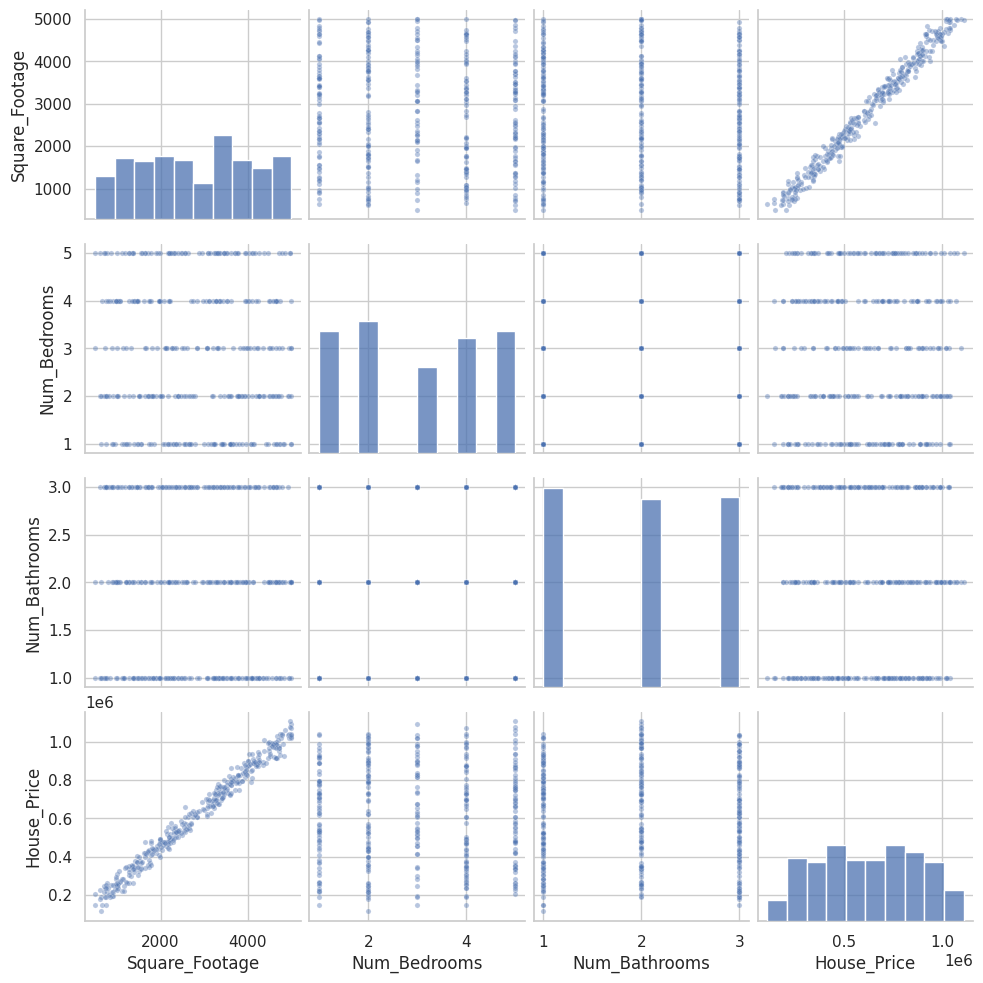

In [12]:
sample_df = df.select_dtypes(include="number").sample(n=min(350, len(df)), random_state=42)
sns.pairplot(sample_df, vars=[c for c in ["Square_Footage", "Num_Bedrooms", "Num_Bathrooms", "House_Price"] if c in sample_df.columns], diag_kind="hist", plot_kws={"alpha": 0.4, "s": 14})
plt.show()

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

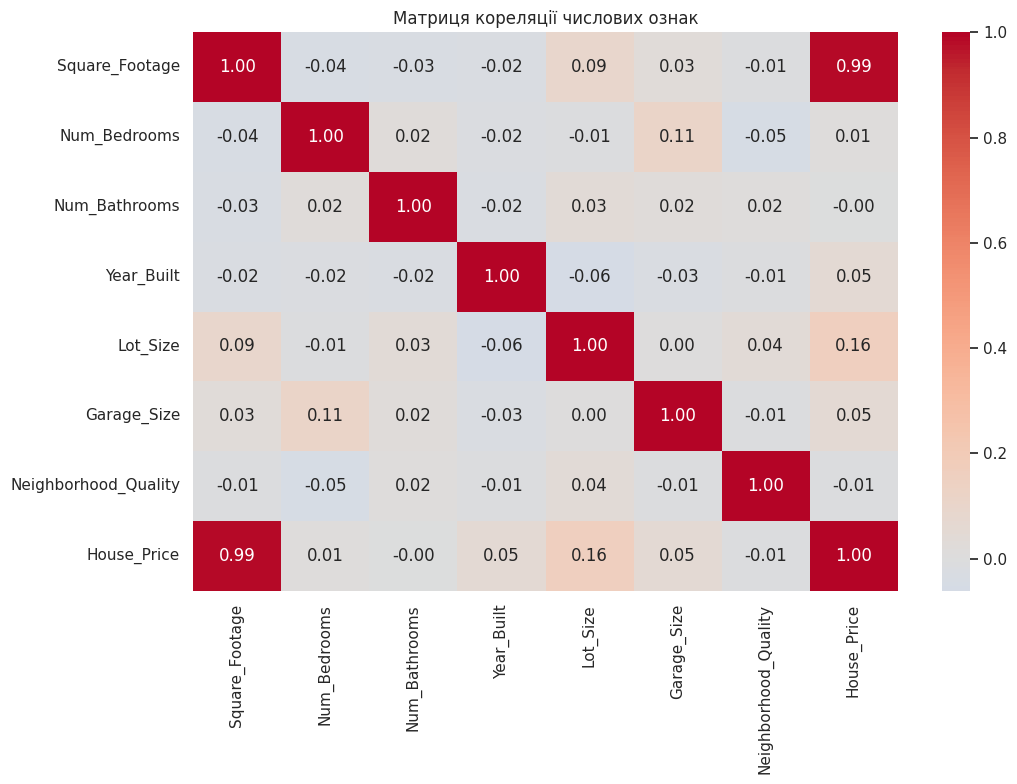

In [13]:
corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Матриця кореляції числових ознак")
plt.tight_layout()
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [14]:
display(corr["House_Price"].sort_values(ascending=False).rename("Кореляція з House_Price").to_frame())

,Кореляція з House_Price
House_Price,1.000000
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [15]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [16]:
data = df.copy()
for column in data.columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")
data = data.dropna(subset=["House_Price"])
X = data.drop(columns="House_Price")
y = data["House_Price"]
print("Ознаки:", list(X.columns))
print("Кількість спостережень:", len(X))

Ознаки: ['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size', 'Garage_Size', 'Neighborhood_Quality']
Кількість спостережень: 1000


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (800, 7)
Тестова вибірка: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [18]:
models = {
    "Linear Regression": Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Ridge": Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Lasso": Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", Lasso(alpha=1.0, max_iter=20000))]),
    "Random Forest": Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))]),
    "Gradient Boosting": Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", GradientBoostingRegressor(random_state=42))])
}
print("Моделі:", ", ".join(models.keys()))

Моделі: Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting


### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [19]:
results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    predictions[name] = predicted
    results.append({"Модель": name, "R²": r2_score(y_test, predicted), "MAE": mean_absolute_error(y_test, predicted), "MSE": mean_squared_error(y_test, predicted)})
results_df = pd.DataFrame(results).sort_values("R²", ascending=False).reset_index(drop=True)
display(results_df.round(3))

,Модель,R²,MAE,MSE
0,Linear Regression,0.998,8174.584,1.014348e+08
1,Lasso,0.998,8174.748,1.014366e+08
2,Ridge,0.998,8241.587,1.024810e+08
3,Gradient Boosting,0.997,12305.218,2.249656e+08
4,Random Forest,0.994,16114.290,3.941317e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

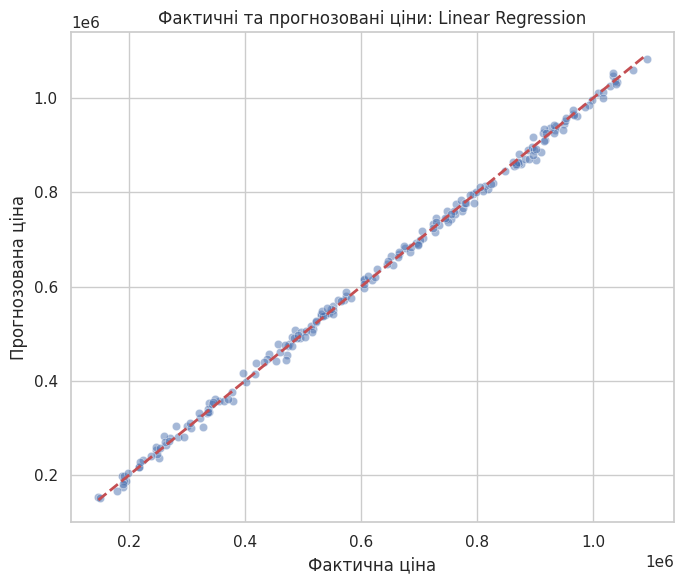

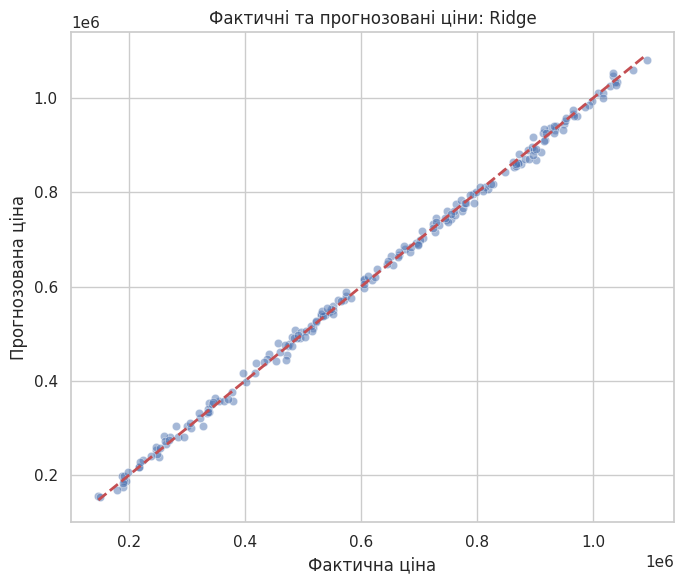

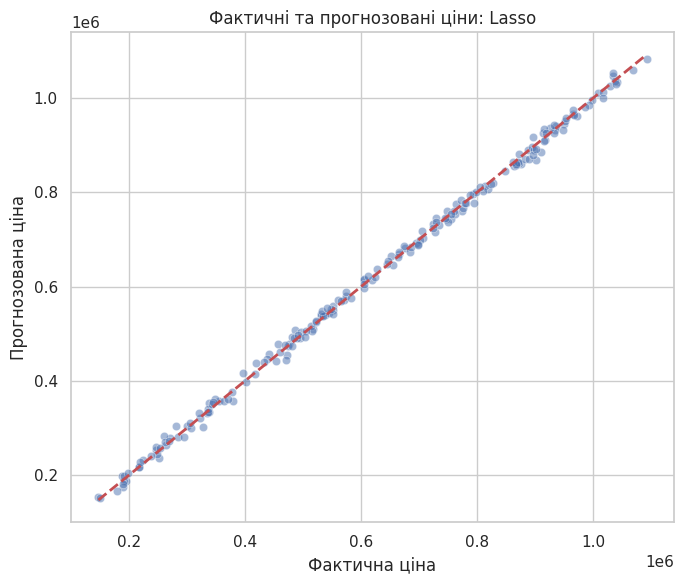

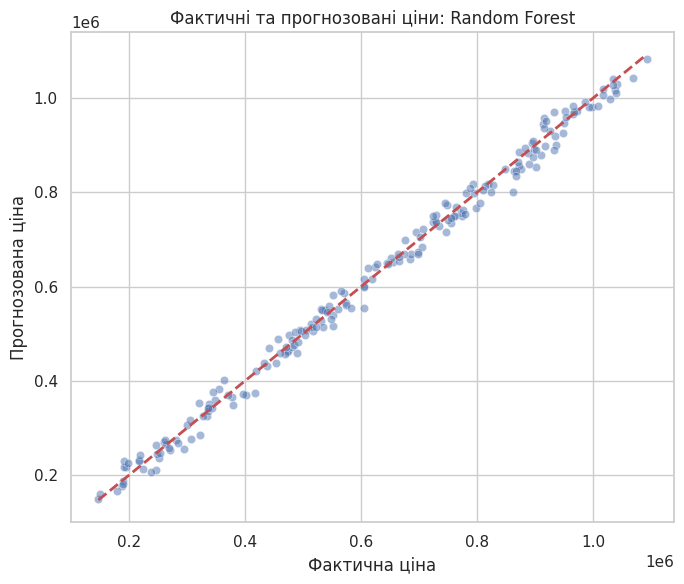

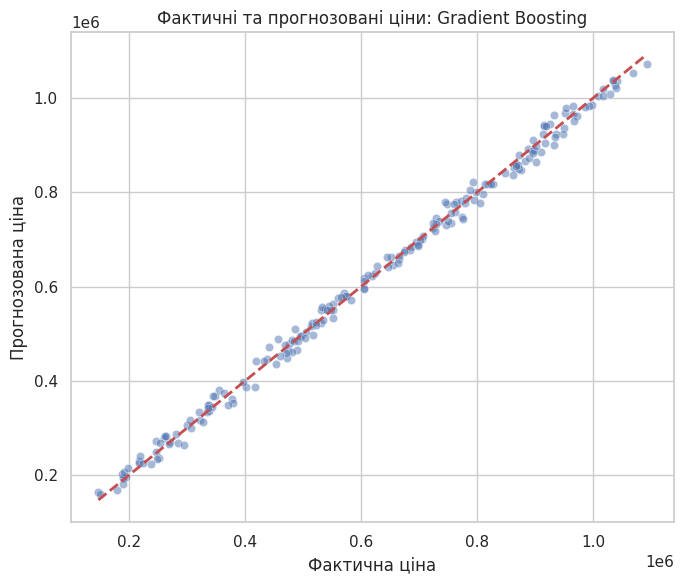

In [20]:
for name, predicted in predictions.items():
    plt.figure(figsize=(7, 6))
    sns.scatterplot(x=y_test, y=predicted, alpha=0.5)
    lower = min(float(y_test.min()), float(predicted.min()))
    upper = max(float(y_test.max()), float(predicted.max()))
    plt.plot([lower, upper], [lower, upper], "r--", linewidth=2)
    plt.title(f"Фактичні та прогнозовані ціни: {name}")
    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.tight_layout()
    plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [21]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_features": ["sqrt", 1.0],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}
search = GridSearchCV(
    estimator=Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", RandomForestRegressor(random_state=42, n_jobs=-1))]),
    param_grid=param_grid,
    scoring="r2",
    cv=3,
    n_jobs=-1,
    refit=True
)
search.fit(X_train, y_train)
print("Найкращі параметри:", search.best_params_)
print(f"Найкращий R² при крос-валідації: {search.best_score_:.4f}")

Найкращі параметри: {'model__max_depth': 10, 'model__max_features': 1.0, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Найкращий R² при крос-валідації: 0.9913


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [22]:
optimized_rf = search.best_estimator_
optimized_predictions = optimized_rf.predict(X_test)
optimized_metrics = {
    "Модель": "Random Forest (оптимізована)",
    "R²": r2_score(y_test, optimized_predictions),
    "MAE": mean_absolute_error(y_test, optimized_predictions),
    "MSE": mean_squared_error(y_test, optimized_predictions)
}
display(pd.DataFrame([optimized_metrics]).round(3))

,Модель,R²,MAE,MSE
0,Random Forest (оптимізована),0.994,16073.021,3.974064e+08


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [23]:
baseline_metrics = results_df.loc[results_df["Модель"] == "Random Forest"].iloc[0].to_dict()
rf_comparison = pd.DataFrame([baseline_metrics, optimized_metrics]).set_index("Модель")
display(rf_comparison.round(3))

,R²,MAE,MSE
Модель,,,
Random Forest,0.994,16114.290,3.941317e+08
Random Forest (оптимізована),0.994,16073.021,3.974064e+08


### Завдання 20. Аналіз оптимізації

Після виконання наступної комірки буде автоматично сформовано висновок на основі отриманих результатів.

In [24]:
before = baseline_metrics
after = optimized_metrics
change = after["R²"] - before["R²"]
quality = "покращилась" if change > 0 else ("не змінилась" if change == 0 else "погіршилась")
recommendation = "доцільно" if change > 0 else "необов'язково"
display(Markdown(f"**Висновок:** Після підбору гіперпараметрів якість Random Forest {quality}. R² змінився з {before['R²']:.4f} до {after['R²']:.4f}, MAE — з {before['MAE']:.2f} до {after['MAE']:.2f}, MSE — з {before['MSE']:.2f} до {after['MSE']:.2f}. Використовувати оптимізовану модель {recommendation}, зважаючи на результати тестової вибірки."))

**Висновок:** Після підбору гіперпараметрів якість Random Forest погіршилась. R² змінився з 0.9939 до 0.9938, MAE — з 16114.29 до 16073.02, MSE — з 394131747.45 до 397406424.17. Використовувати оптимізовану модель необов'язково, зважаючи на результати тестової вибірки.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [25]:
actual = y_test.to_numpy()
predicted = predictions["Linear Regression"]
error_percent = np.where(np.abs(actual) > 1e-10, np.abs(actual - predicted) / np.abs(actual) * 100, np.nan)
forecast_table = pd.DataFrame({"Фактична ціна": actual, "Прогнозована ціна": predicted, "Похибка, %": error_percent})
display(forecast_table.sample(n=min(10, len(forecast_table)), random_state=42).round(2))

,Фактична ціна,Прогнозована ціна,"Похибка, %"
95,1068538.11,1059729.02,0.82
15,194353.74,187868.55,3.34
30,270230.64,279715.82,3.51
158,986006.86,981949.27,0.41
128,953339.73,957382.95,0.42
115,914555.75,909764.27,0.52
69,746167.73,742469.14,0.50
170,646766.29,654445.55,1.19
174,523323.07,524605.44,0.25
45,1008539.16,1011343.64,0.28


## 10. Висновки

Виконайте наступну комірку для формування підсумкового висновку за фактичними результатами моделей.

In [26]:
all_results = pd.concat([results_df, pd.DataFrame([optimized_metrics])], ignore_index=True)
best = all_results.loc[all_results["R²"].idxmax()]
comparison_text = "покращив" if optimized_metrics["R²"] > baseline_metrics["R²"] else "не покращив"
display(Markdown(f"""### Загальний висновок

У роботі було побудовано п'ять регресійних моделей: Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting. Найкращу якість на тестовій вибірці за показником R² показала модель **{best['Модель']}** (R² = **{best['R²']:.4f}**, MAE = **{best['MAE']:.2f}**, MSE = **{best['MSE']:.2f}**).

Підбір гіперпараметрів Random Forest **{comparison_text}** значення R² на тестових даних. Точність прогнозів оцінено за R², MAE та MSE; менші MAE і MSE означають менші помилки, а вище R² — краще пояснення варіації цін.

На якість прогнозування можуть впливати площа будинку, кількість кімнат, рік побудови, характеристики ділянки, якість району, пропущені значення та випадкові коливання ринку. У ході роботи було виконано аналіз даних, побудовано візуалізації, навчено моделі та порівняно їхні результати.
"""))

### Загальний висновок

У роботі було побудовано п'ять регресійних моделей: Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting. Найкращу якість на тестовій вибірці за показником R² показала модель **Linear Regression** (R² = **0.9984**, MAE = **8174.58**, MSE = **101434798.51**).

Підбір гіперпараметрів Random Forest **не покращив** значення R² на тестових даних. Точність прогнозів оцінено за R², MAE та MSE; менші MAE і MSE означають менші помилки, а вище R² — краще пояснення варіації цін.

На якість прогнозування можуть впливати площа будинку, кількість кімнат, рік побудови, характеристики ділянки, якість району, пропущені значення та випадкові коливання ринку. У ході роботи було виконано аналіз даних, побудовано візуалізації, навчено моделі та порівняно їхні результати.
